[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/multigeom/multigeom-tutorials/blob/main/notebooks/f6_which_stimuli_carry_the_information.ipynb)

# Which stimuli carry the information?

* **Author**: simone.azeglio@gmail.com

* **Goal**: Can the bits of a code be assigned to single stimuli? The notebook blurs the stimulus, computes the Fisher information of the blurred code and the local information of Laquitaine, Azeglio et al. (NeurIPS 2025), and compares it with the specific surprise and the stimulus-specific information in a test of locality.

* **Needs**: a CPU, no data. `pip install multigeom`.

* **Time**: about 10 s.

* **Next**: notebook f7 turns the integral of the blurred Fisher information into a metric, the multi-scale Fisher information.

## 1. Setup

### 1.1. Install package

On Google Colab, install `multigeom`. Elsewhere this does nothing.

time: <1 sec

In [1]:
%%time

# on Google Colab install the package from PyPI, without its dependencies: Colab already
# has torch, numpy, scipy and matplotlib, and reinstalling torch is slow and can break
# the GPU runtime (nothing to do on your own machine)
import sys

if "google.colab" in sys.modules:
    %pip install -q --no-deps --pre multigeom

CPU times: user 4 μs, sys: 0 ns, total: 4 μs
Wall time: 5.96 μs


### 1.2. Imports

Import the packages, set the figure style and pick the device. Every tensor is float64, so the device is a CUDA GPU when there is one and the CPU otherwise (Apple's `mps` has no float64).

time: 1 sec

In [2]:
%%time

import math

import matplotlib.pyplot as plt
import torch

from multigeom.lowdim import (
    blur_levels,
    blurred_code,
    compute_fisher,
    compute_g,
    mutual_information,
    specific_surprise,
    stimulus_specific_information,
    to_bits,
)

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_default_dtype(torch.float64)
print("device:", device)

# figure style of the Foundations notebooks: 10 pt text, no top or right spines
plt.rcParams.update(
    {
        "font.size": 10,
        "axes.labelsize": 10,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 9,
        "legend.frameon": False,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

device: cpu
CPU times: user 893 ms, sys: 199 ms, total: 1.09 s
Wall time: 1.79 s


### 1.3. Parameters

The neuron of these notebooks is the bell-shaped neuron $f(x) = e^{-x^2/2}$. Its response to the stimulus $x$ is $r = f(x) + \sigma z$, with $z$ a standard Gaussian and $\sigma = 0.1$, so the response distribution $p(r \mid x)$ is Gaussian with mean $f(x)$ and standard deviation $\sigma$. The stimulus has the uniform prior $p(x) = 1/6$ on $[-3, 3]$. The monotonic twin $m(x)$ equals $f(x)$ for $x < 0$ and $2 - f(x)$ for $x \ge 0$.

All quantities are computed on a grid of stimuli. `N_STIMULI` and `BLUR_PER_DECADE` set the grid of the bell-shaped neuron. They are coarser than the converged grids (1201 stimuli, 100 blur levels per decade) and move the values of this notebook by at most about 0.01 bits.

time: <1 sec

In [3]:
%%time

SIGMA = 0.1  # standard deviation of the response noise
N_STIMULI = 301  # stimuli on [-3, 3]
BLUR_PER_DECADE = 25  # blur levels per decade, from 1e-6 to 1e4

x = torch.linspace(-3, 3, N_STIMULI, device=device)
dx = (x[1] - x[0]).item()
prior = torch.full_like(x, 1 / 6)
bell = torch.exp(-(x**2) / 2)
twin = torch.where(x < 0, bell, 2 - bell)
blur = blur_levels(1e-6, 1e4, BLUR_PER_DECADE, device=device)

TEAL, ROSE, VIOLET, INK, GREY = "#2A8C7E", "#B23A62", "#5b3fd1", "#1a1a1a", "#8a8a8a"


def at(values, x0, grid=x):
    """The value of a quantity on the grid at the grid point closest to x0."""
    return values[(grid - x0).abs().argmin()].item()

CPU times: user 1.07 ms, sys: 3.98 ms, total: 5.06 ms
Wall time: 23.4 ms


## 2. Splitting a number over stimuli

The mutual information $I(R; X)$ is one number. A stimulus-specific information is a function $i(x)$ whose average over the prior is that number, $\int p(x)\, i(x)\, dx = I(R; X)$. Many functions meet this condition. Two established ones are the specific surprise (DeWeese and Meister, 1999), the Kullback-Leibler divergence of the response distribution of $x$ from the distribution of all responses,

$$i_{\mathrm{surp}}(x) = D_{\mathrm{KL}}\big(p(r \mid x) \,\Vert\, p(r)\big),$$

and the stimulus-specific information, SSI (Butts, 2003), the entropy of the prior minus the average entropy of the posterior over the responses to $x$,

$$i_{\mathrm{SSI}}(x) = H(X) - \mathbb{E}_{r \mid x}\big[H(X \mid r)\big].$$

The library returns both in nats, and `to_bits` divides by $\ln 2$. The cell computes them for the bell-shaped neuron, checks their prior averages against the mutual information and compares them at the peak and at $x = -1$ with the Fisher information $J(x) = f'(x)^2/\sigma^2$.

time: <1 sec

In [4]:
%%time

mi_bell = to_bits(mutual_information(x, bell, prior, SIGMA)).item()
surprise_bell = to_bits(specific_surprise(x, bell, prior, SIGMA))
ssi_bell = to_bits(stimulus_specific_information(x, bell, prior, SIGMA))
fisher_bell = compute_fisher(x, bell, SIGMA)

print(f"mutual information: {mi_bell:.3f} bits")
for name, values in (("specific surprise", surprise_bell), ("SSI", ssi_bell)):
    average = torch.trapezoid(prior * values, x).item()
    print(
        f"{name:17s}: prior average {average:.3f} bits | x = 0: {at(values, 0):.2f}"
        f" bits | x = -1: {at(values, -1):.2f} bits"
    )
print(
    f"Fisher information: x = 0: {at(fisher_bell, 0):.1f} | x = -1: "
    f"{at(fisher_bell, -1):.1f}"
)

mutual information: 1.603 bits
specific surprise: prior average 1.598 bits | x = 0: 2.34 bits | x = -1: 2.04 bits
SSI              : prior average 1.607 bits | x = 0: 2.21 bits | x = -1: 1.98 bits
Fisher information: x = 0: 0.0 | x = -1: 36.8
CPU times: user 12.1 ms, sys: 6.49 ms, total: 18.6 ms
Wall time: 51.4 ms


Both measures average to the mutual information, 1.60 bits, and both put more bits at the peak (2.34 and 2.21 bits) than at $x = -1$ (2.04 and 1.98 bits), where the Fisher information is largest. At the peak the Fisher information is zero. The rest of the notebook builds a third split, the local information of Laquitaine, Azeglio et al. (NeurIPS 2025), and tests which of the three depends only on the code near each stimulus.

## 3. The code seen through blur

We blur the stimulus, $x_t = x + \sqrt{t}\, z'$, with $z'$ a standard Gaussian, $t$ the blur level and $\sqrt{t}$ the blur width. An observer who knows only $x_t$ sees the responses of all the stimuli that could have produced it, weighted by the posterior $p(x \mid x_t)$. For this observer the response distribution is the blurred code

$$p_t(r \mid x_t) = \int p(r \mid x)\, p(x \mid x_t)\, dx,$$

and its Fisher information is $J_t(x_t) = \mathbb{E}_{r \mid x_t}\big[(\partial_{x_t} \ln p_t(r \mid x_t))^2\big]$, with $J_0 = J$. `blurred_code` returns the mean of the blurred code, its standard deviation and $J_t$ at one blur level. The cell computes them at $t = 0$, 0.3 and 3.

time: <1 sec

t = 0.0: largest J_t 36.778 | J_t(0) = 0.0e+00
t = 0.3: largest J_t 2.794 | J_t(0) = 6.9e-03
t = 3.0: largest J_t 0.084 | J_t(0) = 1.8e-04


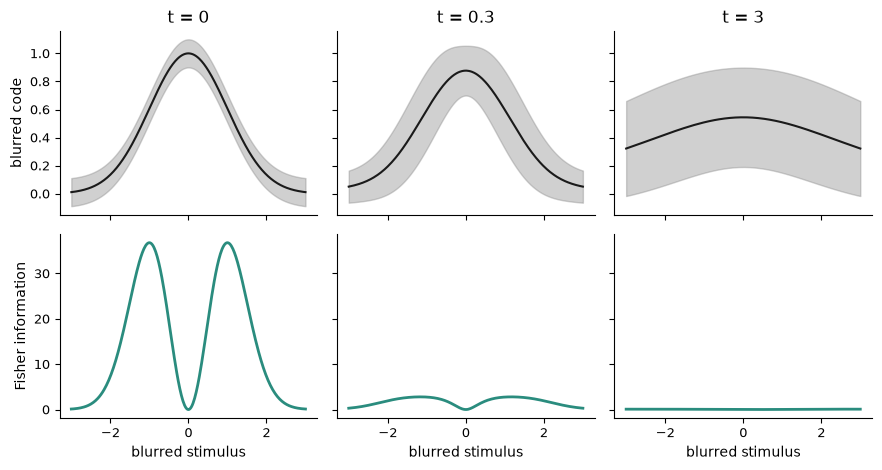

CPU times: user 211 ms, sys: 20.2 ms, total: 231 ms
Wall time: 286 ms


In [5]:
%%time

SHOWN_T = (0.0, 0.3, 3.0)
blurred_codes = {t: blurred_code(x, bell, prior, SIGMA, t) for t in SHOWN_T}
largest_blurred_fisher = {
    t: code.fisher.max().item() for t, code in blurred_codes.items()
}
for t, code in blurred_codes.items():
    print(
        f"t = {t}: largest J_t {largest_blurred_fisher[t]:.3f} | J_t(0) = "
        f"{at(code.fisher, 0):.1e}"
    )

fig, axes = plt.subplots(2, 3, figsize=(9, 4.8), sharex=True, sharey="row")
for col, (t, code) in enumerate(blurred_codes.items()):
    mean, std = code.mean.cpu(), code.std.cpu()
    axes[0, col].fill_between(x.cpu(), mean - std, mean + std, color=GREY, alpha=0.4)
    axes[0, col].plot(x.cpu(), mean, color=INK)
    axes[0, col].set_title(f"t = {t:g}")
    axes[1, col].plot(x.cpu(), code.fisher.cpu(), color=TEAL, lw=2)
    axes[1, col].set_xlabel("blurred stimulus")
axes[0, 0].set_ylabel("blurred code")
axes[1, 0].set_ylabel("Fisher information")
fig.tight_layout()
plt.show()

Top: the mean of the blurred code with a band of one standard deviation. Bottom: $J_t$, on one scale for the three columns. As the blur grows, the blurred tuning curve flattens and its spread widens. The largest $J_t$ falls from 36.8 to 2.8 and 0.084. $J_t$ stays zero at $x_t = 0$, because the blurred code is symmetric about 0 like the tuning curve.

## 4. Information as Fisher information over scales

The information that the response carries about the blurred stimulus, $I(R; X_t)$, equals $I(R; X)$ at $t = 0$ and falls to zero as the blur grows. Laquitaine, Azeglio et al. (NeurIPS 2025) showed that it falls at a rate set by the average of $J_t$ over the blurred stimuli, so that

$$I(R; X) = \frac{1}{2 \ln 2} \int_0^\infty \mathbb{E}_{x_t}\big[J_t(x_t)\big]\, dt \quad \text{bits}.$$

The average over blurred stimuli can be grouped by the stimulus that each blurred stimulus came from, $\mathbb{E}_{x_t}[J_t(x_t)] = \int p(x)\,(\varphi_t * J_t)(x)\, dx$, where $\varphi_t$ is the Gaussian density of variance $t$ and $(\varphi_t * J_t)(x) = \mathbb{E}_{z'}[J_t(x + \sqrt{t}\, z')]$ is a convolution. `compute_g(..., keep_terms=True)` returns these per-scale terms on the grid of stimuli and blur levels. The cell averages them over the prior and integrates over $t$.

time: <1 sec

In [6]:
%%time

bell_g = compute_g(x, bell, prior, SIGMA, blur, keep_terms=True)
rate = torch.trapezoid(
    prior * bell_g.terms, x, dim=1
)  # E_{x_t}[J_t], one per blur level
info_from_fisher = torch.trapezoid(rate, blur).item() / (2 * math.log(2))
print(f"integral of the average J_t over blur levels: {info_from_fisher:.3f} bits")
print(f"mutual information computed directly:          {mi_bell:.3f} bits")

lost = blur * rate / (2 * math.log(2))  # bits lost per unit of ln t
print(f"information lost fastest at t = {blur[lost.argmax()].item():.2f}")

integral of the average J_t over blur levels: 1.607 bits
mutual information computed directly:          1.603 bits
information lost fastest at t = 0.29
CPU times: user 485 ms, sys: 149 ms, total: 633 ms
Wall time: 496 ms


The two numbers agree to 0.004 bits on this grid (0.001 bits on the converged one). The Fisher information alone is the $t = 0$ term of the integral. The identity needs the Fisher information of the blurred code at every blur level, and the bell-shaped neuron loses its bits fastest near $t = 0.3$, a blur width of about 0.55.

## 5. Local information

Swapping the integral over $t$ and the average over stimuli gives one value per stimulus, the local information

$$i(x) = \frac{1}{2 \ln 2} \int_0^\infty (\varphi_t * J_t)(x)\, dt \quad \text{bits},$$

whose prior average is $I(R; X)$ by construction. $i(x)$ is never negative, since $J_t$ is an average of squares. Laquitaine, Azeglio et al. (NeurIPS 2025) show that it also meets locality: a change of the code far from $x$ changes $i(x)$ little, and less the farther away the change is. Section 6 tests this.

`compute_g` returns `local_information` in nats. The cell converts it to bits and reads it for the bell-shaped neuron and its twin.

time: <1 sec

In [7]:
%%time

local_bell = to_bits(bell_g.local_information)
twin_g = compute_g(x, twin, prior, SIGMA, blur)
local_twin = to_bits(twin_g.local_information)

peak = (x.abs() > 0.5) & (x < 0)
x_of_max = x[peak][local_bell[peak].argmax()].item()
print(
    f"bell: i(-1) = {at(local_bell, -1):.2f}, largest {local_bell.max().item():.2f} at "
    f"x = {x_of_max:.2f}, i(0) = {at(local_bell, 0):.2f}, i(-3) = "
    f"{at(local_bell, -3):.2f} bits"
)
print(
    f"bell: prior average {torch.trapezoid(prior * local_bell, x).item():.3f} bits, "
    f"mutual information {mi_bell:.3f} bits"
)
print(f"twin: i(0) = {at(local_twin, 0):.2f}, i(-1) = {at(local_twin, -1):.2f} bits")

bell: i(-1) = 2.37, largest 2.40 at x = -1.12, i(0) = 1.05, i(-3) = 0.58 bits
bell: prior average 1.607 bits, mutual information 1.603 bits
twin: i(0) = 2.52, i(-1) = 3.32 bits
CPU times: user 478 ms, sys: 139 ms, total: 616 ms
Wall time: 510 ms


The flanks carry the most, 2.37 bits at $x = -1$ and 2.40 bits at most, near $|x| = 1.1$. The peak carries 1.05 bits although $J = 0$ there: at blur levels above zero, the blurred versions of $x = 0$ reach the flanks, where the blurred code is sensitive. The ends carry 0.58 bits. The twin, which answers the left-or-right question that the bell-shaped neuron cannot, has 2.52 bits at the peak and 3.32 bits at $x = -1$. On the converged grid these values are 0.01 bits lower (2.39, 1.04, 0.57, 2.51 and 3.31 bits).

### 5.1. Figure: peak or flanks

Top: the Fisher information $J(x)$. Bottom: the local information (rose) with its prior average dashed, and the specific surprise and the SSI (grey) for comparison.

time: <1 sec

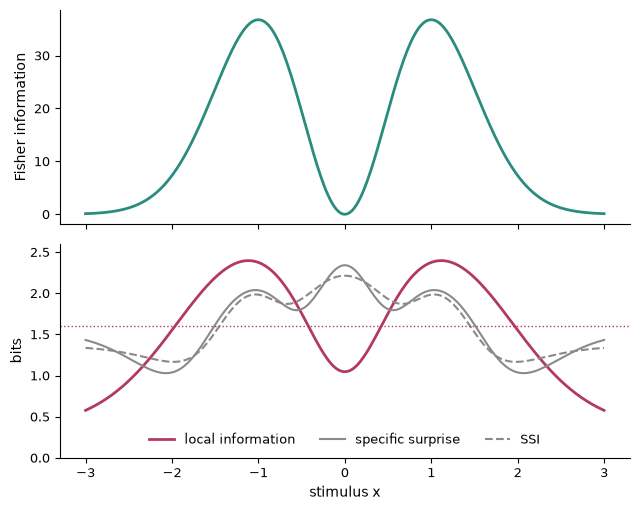

CPU times: user 65.6 ms, sys: 3.28 ms, total: 68.9 ms
Wall time: 69.4 ms


In [8]:
%%time

fig, (top, bottom) = plt.subplots(2, 1, figsize=(6.5, 5.2), sharex=True)
top.plot(x.cpu(), fisher_bell.cpu(), color=TEAL, lw=2)
top.set_ylabel("Fisher information")

bottom.plot(x.cpu(), local_bell.cpu(), color=ROSE, lw=2, label="local information")
bottom.plot(x.cpu(), surprise_bell.cpu(), color=GREY, label="specific surprise")
bottom.plot(x.cpu(), ssi_bell.cpu(), color=GREY, ls="--", label="SSI")
bottom.axhline(mi_bell, color=ROSE, ls=":", lw=1)
bottom.set_ylim(0, 2.6)
bottom.set_xlabel("stimulus x")
bottom.set_ylabel("bits")
bottom.legend(loc="lower center", ncol=3)
fig.tight_layout()
plt.show()

The three curves have the same prior average, 1.60 bits (dotted). The local information follows the Fisher information on the flanks and stays above zero at the peak. The specific surprise and the SSI are largest at the peak.

## 6. The locality test

A neuron has one bump, $b(x) = e^{-(x + 3)^2/2}$, centred at $x = -3$. A second neuron has the same bump and a second identical bump centred at $c = 6$, 10 or 15. The stimulus has a Gaussian prior with mean 6 and standard deviation 8, on the grid $[-24, 36]$, and the noise is $\sigma = 0.1$. The two tuning curves differ only near $c$, so a local measure should change little near $x = -3$.

`LOCALITY_STIMULI` and `LOCALITY_PER_DECADE` set a grid coarser than the converged one (4801 stimuli, 60 blur levels per decade). On it the local information at $x = -3$ is about 0.008 bits higher, and its losses differ from the converged ones by 0.001 bits. The specific surprise and the SSI do not depend on the blur levels and agree to 0.001 bits. The cell computes the four measures for the four codes.

time: 2 secs

In [9]:
%%time

LOCALITY_STIMULI = 601  # stimuli on [-24, 36], a step of 0.1
LOCALITY_PER_DECADE = 10  # blur levels per decade, from 1e-6 to 1e5

y = torch.linspace(-24, 36, LOCALITY_STIMULI, device=device)
wide_prior = torch.exp(-0.5 * ((y - 6) / 8) ** 2)
wide_prior = wide_prior / torch.trapezoid(wide_prior, y)
wide_blur = blur_levels(1e-6, 1e5, LOCALITY_PER_DECADE, device=device)
one_bump = torch.exp(-((y + 3) ** 2) / 2)
codes = {"one": one_bump} | {
    f"c = {c}": one_bump + torch.exp(-((y - c) ** 2) / 2) for c in (6, 10, 15)
}

measures = {}
for name, tuning in codes.items():
    g = compute_g(
        y, tuning, wide_prior, SIGMA, wide_blur, keep_terms=name in ("one", "c = 10")
    )
    measures[name] = {
        "fisher": compute_fisher(y, tuning, SIGMA),
        "local": to_bits(g.local_information),
        "surprise": to_bits(specific_surprise(y, tuning, wide_prior, SIGMA)),
        "SSI": to_bits(stimulus_specific_information(y, tuning, wide_prior, SIGMA)),
        "MI": to_bits(mutual_information(y, tuning, wide_prior, SIGMA)).item(),
        "terms": g.terms,
    }

CPU times: user 2.17 s, sys: 1.12 s, total: 3.29 s
Wall time: 2.56 s


The cell prints the mutual information of each code, the prior average of its local information, and the three complete measures at the peak of the first bump, $x = -3$, and on its flank, $x = -2$.

time: <1 sec

In [10]:
%%time

print(
    f"{'code':7s} {'MI':>5s} {'avg i':>6s} | x = -3: {'local':>5s} {'surp':>5s} "
    f"{'SSI':>5s} | x = -2: {'local':>5s} {'surp':>5s} {'SSI':>5s}"
)
for name, m in measures.items():
    average = torch.trapezoid(wide_prior * m["local"], y).item()
    row = [at(m[k], x0, y) for x0 in (-3, -2) for k in ("local", "surprise", "SSI")]
    print(
        f"{name:7s} {m['MI']:5.2f} {average:6.3f} |        "
        + " ".join(f"{v:5.2f}" for v in row[:3])
        + " |        "
        + " ".join(f"{v:5.2f}" for v in row[3:])
    )

loss_at_peak = {
    name: {
        k: at(measures["one"][k], -3, y) - at(m[k], -3, y)
        for k in ("local", "surprise", "SSI")
    }
    for name, m in measures.items()
    if name != "one"
}
for name, loss in loss_at_peak.items():
    print(
        f"loss at x = -3, {name}: " + ", ".join(f"{k} {v:.2f}" for k, v in loss.items())
    )

code       MI  avg i | x = -3: local  surp   SSI | x = -2: local  surp   SSI
one      0.55  0.554 |         1.49  4.99  4.67 |         2.92  4.68  4.44
c = 6    1.15  1.159 |         1.32  3.47  3.73 |         2.71  3.17  3.50
c = 10   1.10  1.104 |         1.37  3.58  3.71 |         2.78  3.28  3.48
c = 15   0.91  0.918 |         1.42  3.99  3.67 |         2.85  3.69  3.44
loss at x = -3, c = 6: local 0.17, surprise 1.53, SSI 0.93
loss at x = -3, c = 10: local 0.13, surprise 1.41, SSI 0.96
loss at x = -3, c = 15: local 0.07, surprise 1.00, SSI 1.00
CPU times: user 686 μs, sys: 81 μs, total: 767 μs
Wall time: 766 μs


The mutual information grows from 0.55 bits to 1.15, 1.10 and 0.91 bits, because stimuli near $c$ now drive the neuron. The prior average of the local information matches it to within 0.01 bits in every code (0.2% on the converged grid). At the peak, the specific surprise falls from 4.99 bits to 3.47, 3.58 and 3.99 bits. The SSI falls from 4.67 bits to 3.74, 3.71 and 3.67 bits. Each loses about one bit wherever the second bump is. The local information falls from 1.49 bits by 0.17, 0.13 and 0.07 bits, a loss that shrinks as the second bump moves away. For $c = 10$ the loss is 0.126 bits on this grid and 0.125 bits on the converged grid, which rounds to 0.12. On the flank the local information loses 0.21, 0.14 and 0.08 bits.

### 6.1. Figure: the four measures near the first bump

The four measures over $[-7, 1]$ for the one-bump code (solid) and for the code with the second bump at $c = 10$ (dotted).

time: <1 sec

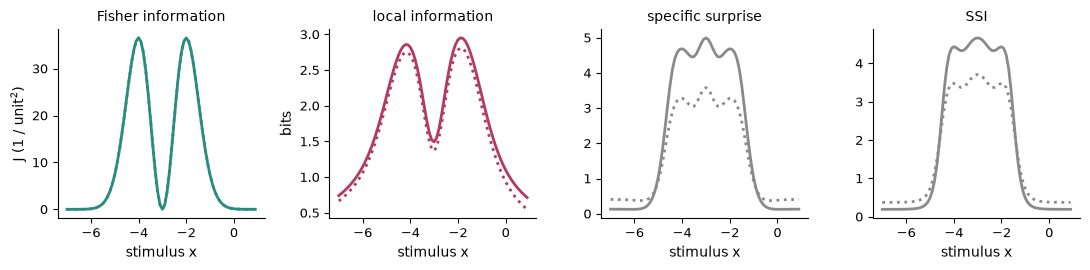

CPU times: user 198 ms, sys: 12.2 ms, total: 210 ms
Wall time: 223 ms


In [11]:
%%time

near = (y >= -7) & (y <= 1)
panels = (
    ("fisher", "Fisher information", TEAL),
    ("local", "local information", ROSE),
    ("surprise", "specific surprise", GREY),
    ("SSI", "SSI", GREY),
)
fig, axes = plt.subplots(1, 4, figsize=(11, 2.8), sharex=True)
for ax, (key, title, colour) in zip(axes, panels):
    ax.plot(y[near].cpu(), measures["one"][key][near].cpu(), color=colour, lw=2)
    ax.plot(
        y[near].cpu(), measures["c = 10"][key][near].cpu(), color=colour, ls=":", lw=2
    )
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("stimulus x")
axes[0].set_ylabel("J (1 / unit$^2$)")
axes[1].set_ylabel("bits")
fig.tight_layout()
plt.show()

The Fisher information is the same for both codes. The local information of the two codes almost coincides. The specific surprise and the SSI of the two-bump code lie about one bit lower around the bump.

### 6.2. The blur levels behind the loss of the local information

The lost bit answers the question "which bump was the stimulus at?". The specific surprise and the SSI charge it in full to the stimuli of the first bump. The local information charges it at coarse blur levels, where the blur spans both bumps and the loss is shared among all the stimuli of that region. The cell splits the loss at $x = -3$, for $c = 10$, by blur level, and gives the loss at three other stimuli.

time: <1 sec

In [12]:
%%time

i_peak = (y + 3).abs().argmin()
term_gap = measures["one"]["terms"][:, i_peak] - measures["c = 10"]["terms"][:, i_peak]
loss_up_to = torch.cumulative_trapezoid(term_gap, wide_blur) / (2 * math.log(2))
loss_up_to = torch.cat([loss_up_to.new_zeros(1), loss_up_to])
total = loss_up_to[-1].item()


def share_below(t):
    return loss_up_to[(wide_blur <= t).nonzero().max()].item() / total


loss_shares = {
    "below t = 3": share_below(3),
    "above t = 10": 1 - share_below(10),
    "above t = 100": 1 - share_below(100),
}
print(
    f"loss at x = -3: {total:.3f} bits | "
    + ", ".join(f"{k}: {v:.0%}" for k, v in loss_shares.items())
)
for x0 in (-6, 0, 3.5):
    gap = at(measures["one"]["local"], x0, y) - at(measures["c = 10"]["local"], x0, y)
    print(f"loss of the local information at x = {x0}: {gap:.2f} bits")

loss at x = -3: 0.126 bits | below t = 3: 0%, above t = 10: 97%, above t = 100: 31%
loss of the local information at x = -6: 0.09 bits
loss of the local information at x = 0: 0.16 bits
loss of the local information at x = 3.5: 0.07 bits
CPU times: user 577 μs, sys: 379 μs, total: 956 μs
Wall time: 4.53 ms


None of the loss comes from blur levels below $t = 3$, 97% from blur levels above $t = 10$, where the blur width exceeds 3, and about 30% from blur levels above $t = 100$. The local information drops by 0.09 bits at $x = -6$, 0.16 bits at $x = 0$ and 0.07 bits at $x = 3.5$: the bit is shared among the stimuli between and around the bumps.

## 7. Try it

1. Move the second bump from $c = 4$ to $c = 16$. The loss of the local information at $x = -3$ falls steadily with the distance, while the loss of the specific surprise is largest at the prior mean $c = 6$ and the loss of the SSI stays near one bit.
2. Raise the noise to $\sigma = 0.5$ in section 1.3. The local information of the bell-shaped neuron moves towards the peak.
3. Replace the uniform prior of the bell-shaped neuron by a Gaussian with standard deviation 1. The local information drops at the ends, where stimuli become rare.

The cell carries out the first change on four positions of the second bump.

time: 2 secs

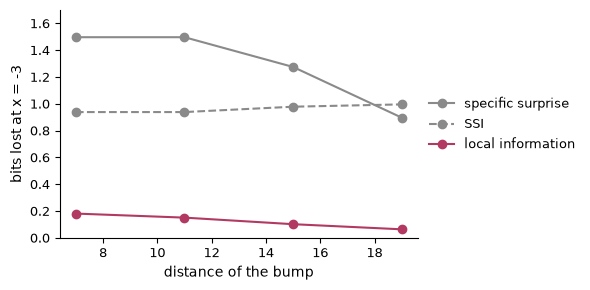

CPU times: user 2.17 s, sys: 1.06 s, total: 3.23 s
Wall time: 2.53 s


In [13]:
%%time

positions = (4, 8, 12, 16)
sweep = {"local": [], "surprise": [], "SSI": []}
for c in positions:
    tuning = one_bump + torch.exp(-((y - c) ** 2) / 2)
    g = compute_g(y, tuning, wide_prior, SIGMA, wide_blur)
    two = {
        "local": to_bits(g.local_information),
        "surprise": to_bits(specific_surprise(y, tuning, wide_prior, SIGMA)),
        "SSI": to_bits(stimulus_specific_information(y, tuning, wide_prior, SIGMA)),
    }
    for k in sweep:
        sweep[k].append(at(measures["one"][k], -3, y) - at(two[k], -3, y))

bump_distance = [c + 3 for c in positions]
plt.figure(figsize=(6, 3))
plt.plot(bump_distance, sweep["surprise"], "o-", color=GREY, label="specific surprise")
plt.plot(bump_distance, sweep["SSI"], "o--", color=GREY, label="SSI")
plt.plot(bump_distance, sweep["local"], "o-", color=ROSE, label="local information")
plt.xlabel("distance of the bump")
plt.ylabel("bits lost at x = -3")
plt.ylim(0, 1.7)
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

The loss of the local information falls from 0.18 bits at a distance of 7 to 0.06 bits at a distance of 19. The other two measures lose about a bit at every distance.